# 11 — Kurasi Dataset dan EDA

**Belum pernah dijalankan.** Jalankan di laptop TUF setelah notebook 01 dan 02 pernah
dijalankan. Notebook ini membaca `data/processed/manifest.csv`, file `split_seed*.json`, dan
`sequences_500x300_fp16.npy` yang dibuat keduanya. Perkiraan durasinya 10–20 menit, tanpa
pelatihan model.

Isinya:

| Bagian | Isi |
|---|---|
| A | Gambaran umum: kelas, kelengkapan pasangan, pembagian train/val/test |
| B | Statistik citra: resolusi, kecerahan, kontras, ketajaman |
| C | Fitur CNN citra (MobileNetV2 *pretrained* ImageNet, tanpa *fine-tune*) |
| D | Statistik teks OCR: panjang, OOV, kata khas per kelas |
| E | Fitur embedding teks (rata-rata FastText) dan komplementaritas dengan citra |
| G | Modalitas hilang atau bising: penanda per dokumen dan per kelas |
| H | Jalan pintas kode ID arsip (Larson et al., 2025) |
| I | Simpan dataset terkurasi dan ringkasan |

Bagian F (perbandingan antar-mesin OCR) ditunda sampai OCR multi-mesin dijalankan.

**Analisis yang memakai label hanya memakai bagian latih (train+val) seed 42.** Ini
mencakup kata khas per kelas, kemiripan antar-kelas, dan classifier kode ID. Data uji
hanya dipakai untuk mengukur akurasi *probe*. Dengan begitu EDA tidak "mengintip" data uji
yang nanti dipakai eksperimen.

**Yang ditulis:**
- `data/processed/manifest_kurasi.csv`;
- `data/interim/eda_*` (cache, supaya Run All kedua cepat);
- `reports/eda_*.csv`;
- `reports/figures/eda_*.png`.

Tidak ada file lama yang ditimpa.

## Pengaturan

In [1]:
SEED = 42                # split acuan untuk analisis yang memakai label
FLAG_PERCENTILE = 5      # ekor distribusi yang ditandai (persen), bukan ambang karangan
DUP_MIN_CORR = 0.98      # korelasi thumbnail 64x64 minimum untuk kandidat duplikat
DUP_MIN_JACCARD = 0.8    # kemiripan teks OCR minimum untuk mengonfirmasi kandidat
STATS_WIDTH = 1000       # lebar seragam (px) saat menghitung statistik citra
TSNE_PERPLEXITY = 30

import json, subprocess, sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src import eda as E
from src import splits as S
from src.config import CONFIG, set_seed
from src.utils import save_fig

set_seed(SEED)
PROC, INTERIM, REPORTS = CONFIG["data_processed"], CONFIG["data_interim"], ROOT / "reports"
INTERIM.mkdir(parents=True, exist_ok=True)
CLASSES = CONFIG["classes"]

manifest = pd.read_csv(PROC / "manifest.csv", dtype={"id": str})
labels = manifest["kelas"].tolist()
y = manifest["kelas"].to_numpy()
splits = {s: S.load_split(s, labels) for s in [42, 43, 44]}
split = splits[SEED]
fit_idx = np.array(sorted(split["train"] + split["val"]))
test_idx = np.array(split["test"])
print(f"{len(manifest)} dokumen | fit {len(fit_idx)} | test {len(test_idx)}")

3482 dokumen | fit 800 | test 2682


## Dependency

Hanya `wordfreq` (daftar kata bahasa Inggris untuk mengukur OOV, ± 30 MB). Dipasang dengan
numpy dan torch dikunci, supaya lingkungan hasil notebook sebelumnya tidak bergeser.

In [2]:
from importlib import metadata
lock = INTERIM / "constraints_eda.txt"
lock.write_text("\n".join(f"{p}=={metadata.version(p)}" for p in ["numpy", "torch", "torchvision"]) + "\n")
%pip install -q wordfreq -c "{lock}"
from wordfreq import zipf_frequency
assert np.__version__ == metadata.version("numpy"), "numpy berubah! Hentikan dan laporkan."
print("wordfreq siap, numpy", np.__version__)

Note: you may need to restart the kernel to use updated packages.
wordfreq siap, numpy 1.26.4


## A. Gambaran umum

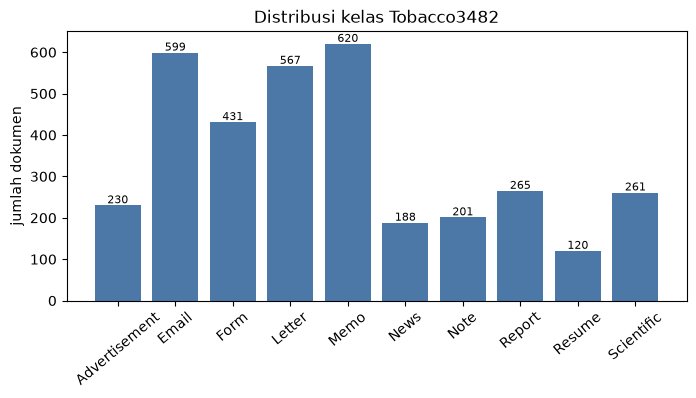

rasio kelas terbesar : terkecil = 5.17
citra ada: 3482/3482 | teks ada: 3482/3482


In [3]:
counts = manifest["kelas"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts.index, counts.values, color="#4C78A8")
ax.set_ylabel("jumlah dokumen")
ax.set_title("Distribusi kelas Tobacco3482")
ax.tick_params(axis="x", rotation=40)
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha="center", fontsize=8)
save_fig(fig, "eda_distribusi_kelas")
plt.show()
print(f"rasio kelas terbesar : terkecil = {counts.max() / counts.min():.2f}")

exists_img = manifest["path_citra"].map(lambda p: Path(p).exists())
exists_txt = manifest["path_teks"].map(lambda p: Path(p).exists())
print(f"citra ada: {exists_img.sum()}/{len(manifest)} | teks ada: {exists_txt.sum()}/{len(manifest)}")
assert exists_img.all() and exists_txt.all(), "ada file yang hilang — jalankan notebook 01"

In [4]:
rows = []
for s, sp in splits.items():
    for part in ["train", "val", "test"]:
        rows.append({"seed": s, "bagian": part, **pd.Series(y[sp[part]]).value_counts()
                     .reindex(CLASSES, fill_value=0).to_dict(), "total": len(sp[part])})
split_table = pd.DataFrame(rows)
display(split_table)

,seed,bagian,Advertisement,Email,Form,Letter,Memo,News,Note,Report,Resume,Scientific,total
0,42,train,48,124,89,117,128,39,41,55,25,54,720
1,42,val,5,14,10,13,14,4,5,6,3,6,80
2,42,test,177,461,332,437,478,145,155,204,92,201,2682
3,43,train,48,124,89,117,128,39,41,55,25,54,720
4,43,val,5,14,10,13,14,4,5,6,3,6,80
5,43,test,177,461,332,437,478,145,155,204,92,201,2682
6,44,train,48,124,89,117,128,39,41,55,25,54,720
7,44,val,5,14,10,13,14,4,5,6,3,6,80
8,44,test,177,461,332,437,478,145,155,204,92,201,2682


## B. Statistik citra

Setiap halaman diubah ke grayscale dan lebar seragam 1000 px sebelum diukur, supaya
ketajaman (variansi Laplacian) bisa dibandingkan antar-halaman. DPI diperkirakan dari
lebar asli dibagi 8,5 inci (ukuran *letter* AS).

In [5]:
cache, cache_thumb = INTERIM / "eda_citra.csv", INTERIM / "eda_thumb64.npy"
if cache.exists() and cache_thumb.exists():
    img = pd.read_csv(cache, dtype={"id": str})
    thumbs = np.load(cache_thumb)
else:
    rows, thumbs, t0 = [], [], time.perf_counter()
    for i, (doc_id, path) in enumerate(zip(manifest["id"], manifest["path_citra"])):
        with Image.open(path) as im:
            w, h = im.size
            g = im.convert("L")
            small = np.asarray(g.resize((STATS_WIDTH, round(h * STATS_WIDTH / w))))
            thumbs.append(E.thumbnail_vector(np.asarray(g.resize((64, 64)))))
        rows.append({"id": doc_id, "lebar": w, "tinggi": h,
                     **E.image_stats(small, w)})
        if (i + 1) % 500 == 0:
            print(f"{i + 1}/{len(manifest)}  {time.perf_counter() - t0:.0f} dtk")
    img = pd.DataFrame(rows)
    thumbs = np.stack(thumbs)
    img.to_csv(cache, index=False)
    np.save(cache_thumb, thumbs)
img["kelas"] = y
display(img[["lebar", "tinggi", "dpi_perkiraan", "kecerahan", "kontras",
             "rasio_tinta", "ketajaman"]].describe().round(2))

500/3482  28 dtk
1000/3482  56 dtk
1500/3482  90 dtk
2000/3482  123 dtk
2500/3482  156 dtk
3000/3482  189 dtk


,lebar,tinggi,dpi_perkiraan,kecerahan,kontras,rasio_tinta,ketajaman
count,3482.00,3482.00,3482.00,3482.00,3482.00,3482.00,3482.00
mean,2094.62,2728.71,246.43,238.38,48.74,0.06,4818.86
std,426.24,523.35,50.15,20.82,21.37,0.08,3583.01
min,817.00,1089.00,96.12,20.17,7.06,0.00,108.33
25%,1728.00,2292.00,203.29,236.14,34.52,0.02,2378.65
50%,1728.00,2292.00,203.29,243.26,47.10,0.05,4166.28
75%,2544.00,3290.00,299.29,248.74,59.10,0.07,6233.89
max,3520.00,4400.00,414.12,254.75,125.85,0.92,33640.49


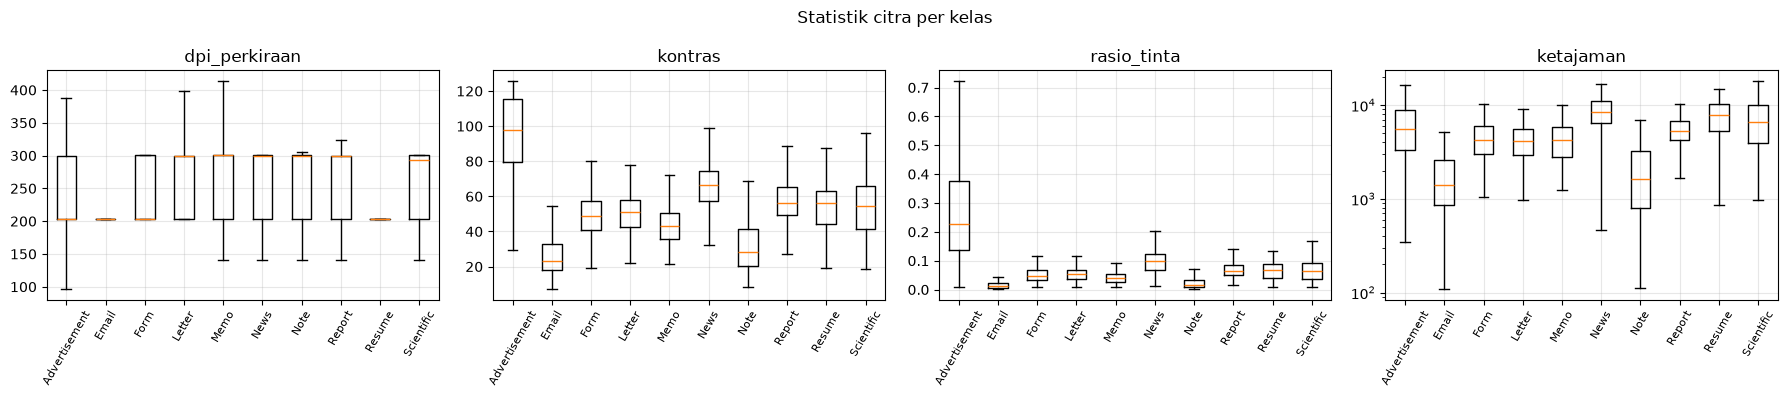

In [6]:
cols = ["dpi_perkiraan", "kontras", "rasio_tinta", "ketajaman"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cols):
    ax.boxplot([img.loc[img.kelas == k, col] for k in CLASSES], showfliers=False)
    ax.set_xticks(range(1, len(CLASSES) + 1), CLASSES, rotation=60, fontsize=8)
    ax.set_title(col)
    ax.grid(alpha=0.3)
axes[3].set_yscale("log")
fig.suptitle("Statistik citra per kelas")
fig.tight_layout()
save_fig(fig, "eda_statistik_citra")
plt.show()

## C. Fitur CNN citra

Vektor 1280 dimensi dari MobileNetV2 berbobot ImageNet, **tanpa** *fine-tune*, dengan
praproses yang sama seperti eksperimen ($384\times384$, di-*warp*). Tiga pengamatan:

1. **t-SNE**: apakah kelas sudah mengelompok tanpa pelatihan apa pun?
2. **Kemiripan antar-pusat kelas**: pasangan kelas mana yang tampak mirip bagi citra?
3. **Probe linear**: regresi logistik di atas fitur beku, dilatih pada bagian fit dan diuji
   pada test. Ini ukuran keterpisahan, bukan model akhir.

In [7]:
import torch
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from src import datasets as DS
from src.models import ImageBranch, build_transform

cache = INTERIM / "eda_cnn_mobilenetv2.npy"
if cache.exists():
    f_img = np.load(cache)
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = ImageBranch(pretrained=True).to(device).eval()
    ds = DS.ImageDataset(manifest["path_citra"].tolist(), np.zeros(len(manifest), dtype=int),
                         list(range(len(manifest))), build_transform())
    loader = torch.utils.data.DataLoader(ds, batch_size=16, num_workers=CONFIG["num_workers"])
    out, t0 = [], time.perf_counter()
    with torch.no_grad(), torch.autocast(device.type, enabled=device.type == "cuda"):
        for x, _ in loader:
            out.append(model.features(x.to(device)).float().cpu().numpy())
    f_img = np.concatenate(out)
    np.save(cache, f_img)
    print(f"ekstraksi {f_img.shape} selesai dalam {time.perf_counter() - t0:.0f} dtk di {device}")
print("fitur citra:", f_img.shape)

def probe(features, name):
    sc = StandardScaler().fit(features[fit_idx])
    clf = LogisticRegression(max_iter=3000).fit(sc.transform(features[fit_idx]), y[fit_idx])
    pred = clf.predict(sc.transform(features[test_idx]))
    per_class = f1_score(y[test_idx], pred, labels=CLASSES, average=None)
    return {"fitur": name, "oa_probe": (pred == y[test_idx]).mean(),
            "macro_f1_probe": f1_score(y[test_idx], pred, average="macro")}, per_class

def tsne(features):
    z = PCA(50, random_state=SEED).fit_transform(StandardScaler().fit_transform(features))
    return TSNE(2, perplexity=TSNE_PERPLEXITY, random_state=SEED, init="pca").fit_transform(z)

majority = (y[test_idx] == pd.Series(y[fit_idx]).mode()[0]).mean()
probe_img, f1_img = probe(f_img, "citra: MobileNetV2 pretrained")
z_img = tsne(f_img)
print(f"probe citra: OA {probe_img['oa_probe']:.4f}, macro F1 {probe_img['macro_f1_probe']:.4f} "
      f"(kelas mayoritas {majority:.4f})")

ekstraksi (3482, 1280) selesai dalam 301 dtk di cuda
fitur citra: (3482, 1280)
probe citra: OA 0.7293, macro F1 0.7099 (kelas mayoritas 0.1782)


## D. Statistik teks OCR (QS-OCR)

- **Panjang**: jumlah kata per dokumen.
- **OOV**: bagian kata alfabetik ≥ 4 huruf yang tidak ada di daftar kata `wordfreq`. Daftar
  ini longgar, sehingga salah baca yang kebetulan berupa kata (mis. `tbe`) tidak
  terhitung: angkanya **batas bawah** galat.
- **Kata khas per kelas**: TF-IDF yang dihitung dari bagian fit saja.

,n_kata,n_kata_alfabet,oov
count,3482.000,3482.000,3429.000
mean,223.871,212.039,0.098
std,200.950,196.456,0.137
min,0.000,0.000,0.000
25%,88.000,80.000,0.025
50%,174.000,160.000,0.055
75%,293.000,281.000,0.111
max,1579.000,1573.000,1.000


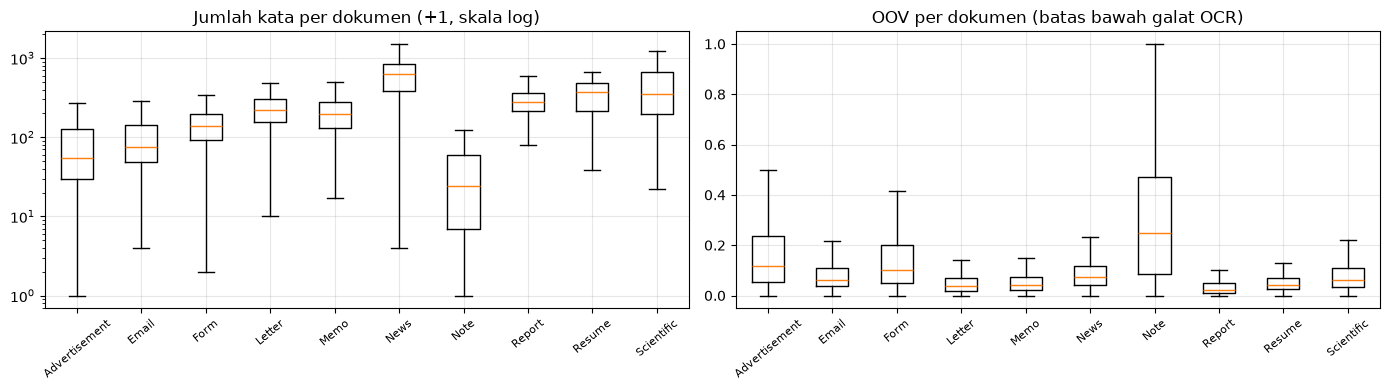

In [8]:
from functools import lru_cache
from src.ocr import oov_share, words

@lru_cache(maxsize=None)
def known(w):
    return zipf_frequency(w, "en") > 0

texts = [Path(p).read_text(encoding="utf-8", errors="replace") for p in manifest["path_teks"]]
txt = pd.DataFrame({
    "id": manifest["id"], "kelas": y,
    "n_kata": [len(t.split()) for t in texts],
    "n_kata_alfabet": [len(words(t)) for t in texts],
    "oov": [oov_share(t, known) for t in texts],
    "n_kode_id": [len(E.id_codes(t)) for t in texts],
})
display(txt[["n_kata", "n_kata_alfabet", "oov"]].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].boxplot([txt.loc[txt.kelas == k, "n_kata"] + 1 for k in CLASSES], showfliers=False)
axes[0].set_yscale("log")
axes[0].set_title("Jumlah kata per dokumen (+1, skala log)")
axes[1].boxplot([txt.loc[txt.kelas == k, "oov"].dropna() for k in CLASSES], showfliers=False)
axes[1].set_title("OOV per dokumen (batas bawah galat OCR)")
for ax in axes:
    ax.set_xticks(range(1, len(CLASSES) + 1), CLASSES, rotation=40, fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, "eda_statistik_teks")
plt.show()

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", lowercase=True,
                      stop_words="english", min_df=3, sublinear_tf=True)
X_fit = vec.fit_transform([texts[i] for i in fit_idx])
vocab = np.array(vec.get_feature_names_out())
top_terms = {}
for k in CLASSES:
    rows = np.flatnonzero(y[fit_idx] == k)
    mean = np.asarray(X_fit[rows].mean(axis=0)).ravel()
    top_terms[k] = ", ".join(vocab[np.argsort(mean)[::-1][:10]])
top_terms = pd.Series(top_terms, name="10 kata TF-IDF tertinggi (bagian fit)")
display(top_terms.to_frame())

,10 kata TF-IDF tertinggi (bagian fit)
Advertisement,"warning, surgeon, cigarette, general, advertis..."
Email,"sent, subject, message, original, wednesday, d..."
Form,"date, fax, number, pages, form, total, morris,..."
Letter,"tobacco, dear, research, new, sincerely, york,..."
Memo,"correspondence, attached, philip, morris, memo..."
News,"said, smoking, health, smoke, tobacco, smokers..."
Note,"desk, information, james, ore, web, ous, chris..."
Report,"tobacco, smoking, cigarette, products, product..."
Resume,"university, research, biology, assistant, prof..."
Scientific,"cell, cells, research, results, study, induced..."


## E. Fitur embedding teks dan komplementaritas

Vektor dokumen = rata-rata vektor FastText kata-katanya, diambil dari sekuens yang sudah
disimpan notebook 02, sehingga model FastText 15 GB tidak perlu dimuat ulang.

Grafik terakhir membandingkan F1 *probe* per kelas antara citra dan teks. Kelas yang jauh
lebih mudah dipisahkan oleh teks adalah tempat modalitas teks diharapkan menyumbang paling
banyak.

In [10]:
seq = np.load(PROC / "sequences_500x300_fp16.npy", mmap_mode="r")
f_txt = np.concatenate([E.mean_nonzero_rows(seq[i:i + 256]) for i in range(0, len(seq), 256)])
del seq
print("fitur teks:", f_txt.shape, "| dokumen dengan vektor nol:", int((~f_txt.any(axis=1)).sum()))

probe_txt, f1_txt = probe(f_txt, "teks: rata-rata FastText")
z_txt = tsne(f_txt)
probe_table = pd.DataFrame([probe_img, probe_txt]).round(4)
probe_table["kelas_mayoritas"] = round(majority, 4)
display(probe_table)

fitur teks: (3482, 300) | dokumen dengan vektor nol: 27


,fitur,oa_probe,macro_f1_probe,kelas_mayoritas
0,citra: MobileNetV2 pretrained,0.7293,0.7099,0.1782
1,teks: rata-rata FastText,0.6685,0.6491,0.1782


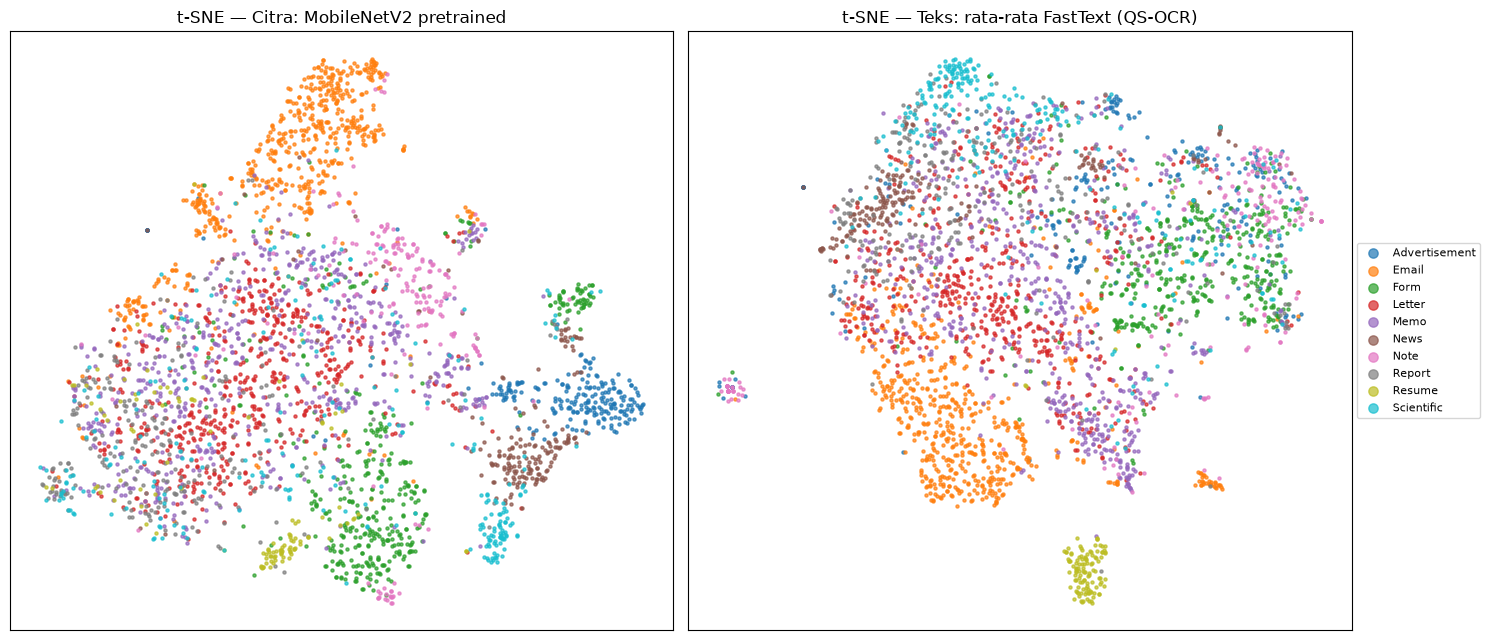

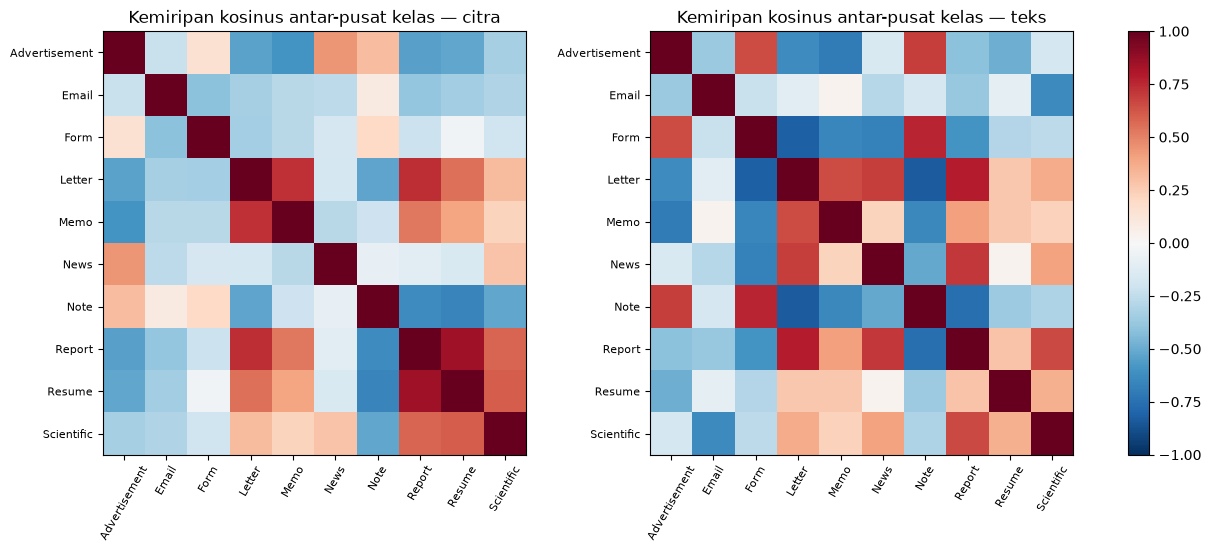

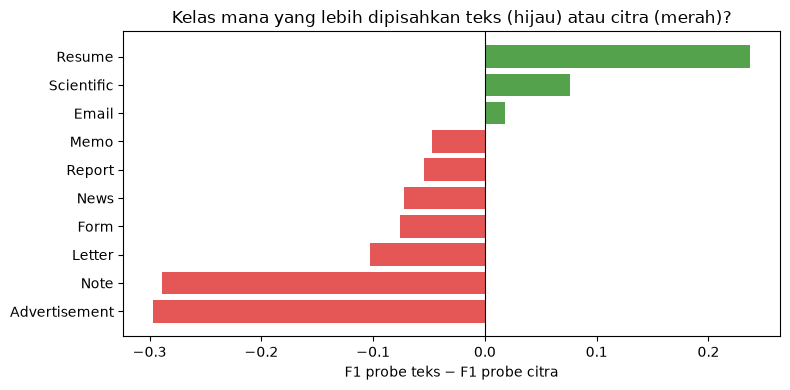

,f1_citra,f1_teks,teks_minus_citra
Advertisement,0.886,0.589,-0.297
Note,0.686,0.397,-0.289
Letter,0.727,0.624,-0.103
Form,0.813,0.737,-0.076
News,0.837,0.764,-0.072
Report,0.421,0.366,-0.055
Memo,0.674,0.627,-0.048
Email,0.899,0.918,0.018
Scientific,0.446,0.523,0.076
Resume,0.710,0.947,0.237


In [11]:
colors = plt.cm.tab10(np.arange(len(CLASSES)))
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, z, title in [(axes[0], z_img, "Citra: MobileNetV2 pretrained"),
                     (axes[1], z_txt, "Teks: rata-rata FastText (QS-OCR)")]:
    for k, c in zip(CLASSES, colors):
        m = y == k
        ax.scatter(z[m, 0], z[m, 1], s=5, color=c, label=k, alpha=0.7)
    ax.set_title(f"t-SNE — {title}")
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=3, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
save_fig(fig, "eda_tsne_citra_teks")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, f, title in [(axes[0], f_img, "citra"), (axes[1], f_txt, "teks")]:
    cc = E.centroid_cosine(StandardScaler().fit(f[fit_idx]).transform(f[fit_idx]),
                           y[fit_idx], CLASSES)
    im = ax.imshow(cc, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=60, fontsize=8)
    ax.set_yticks(range(len(CLASSES)), CLASSES, fontsize=8)
    ax.set_title(f"Kemiripan kosinus antar-pusat kelas — {title}")
fig.colorbar(im, ax=axes, fraction=0.025)
save_fig(fig, "eda_kemiripan_kelas")
plt.show()

comp = pd.DataFrame({"f1_citra": f1_img, "f1_teks": f1_txt}, index=CLASSES)
comp["teks_minus_citra"] = comp.f1_teks - comp.f1_citra
comp = comp.sort_values("teks_minus_citra")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(comp.index, comp.teks_minus_citra,
        color=np.where(comp.teks_minus_citra > 0, "#54A24B", "#E45756"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("F1 probe teks − F1 probe citra")
ax.set_title("Kelas mana yang lebih dipisahkan teks (hijau) atau citra (merah)?")
fig.tight_layout()
save_fig(fig, "eda_komplementaritas")
plt.show()
display(comp.round(3))

## G. Modalitas hilang atau bising

Setiap penanda ditentukan dari **ekor distribusi** (`FLAG_PERCENTILE` persen), bukan dari
ambang yang dipilih sebelum melihat data:

| Penanda | Arti |
|---|---|
| `flag_teks_kosong` | OCR tidak menghasilkan kata sama sekali (modalitas teks **hilang**) |
| `flag_teks_pendek` | jumlah kata di ekor bawah, di antara dokumen yang tidak kosong |
| `flag_oov_tinggi` | OOV di ekor atas (teks **bising**) |
| `flag_resolusi_rendah` | perkiraan DPI di ekor bawah |
| `flag_buram` | ketajaman di ekor bawah (citra **bising**) |
| `flag_duplikat` | nyaris identik dengan dokumen lain: korelasi thumbnail ≥ `DUP_MIN_CORR` **dan** teks OCR mirip (Jaccard ≥ `DUP_MIN_JACCARD`) |

Duplikat dicek dua tahap karena halaman dokumen sebagian besar putih: kemiripan citra saja
akan menyamakan formulir yang berbeda isinya tetapi bertemplat sama.

Dokumen yang tertandai **tidak dibuang**: derau OCR adalah objek penelitian. Duplikat yang
melintasi train dan test dicatat per seed, karena itu kebocoran data.

In [12]:
df = txt.merge(img.drop(columns="kelas"), on="id")
assert (df["id"] == manifest["id"]).all()

df["flag_teks_kosong"] = df.n_kata_alfabet == 0
nonempty = np.where(df.flag_teks_kosong, np.nan, df.n_kata_alfabet)
df["flag_teks_pendek"], thr_short = E.flag_tail(nonempty, FLAG_PERCENTILE)
df["flag_oov_tinggi"], thr_oov = E.flag_tail(df.oov.to_numpy(float), FLAG_PERCENTILE, upper=True)
df["flag_resolusi_rendah"], thr_dpi = E.flag_tail(df.dpi_perkiraan.to_numpy(), FLAG_PERCENTILE)
df["flag_buram"], thr_sharp = E.flag_tail(df.ketajaman.to_numpy(), FLAG_PERCENTILE)

from src.ocr import jaccard
candidates = E.near_duplicates(thumbs, DUP_MIN_CORR)
def text_agrees(i, j):
    jac = jaccard(texts[i], texts[j])
    return jac is None or jac >= DUP_MIN_JACCARD     # None = both pages have no text
pairs = [p for p in candidates if text_agrees(p[0], p[1])]
dup = np.zeros(len(df), bool)
for i, j, _ in pairs:
    dup[[i, j]] = True
df["flag_duplikat"] = dup
for s, sp in splits.items():
    leak = np.zeros(len(df), bool)
    for i, j in E.split_leaks(pairs, sp):
        leak[[i, j]] = True
    df[f"bocor_s{s}"] = leak

thresholds = {"teks_pendek_maks_kata": thr_short, "oov_tinggi_min": thr_oov,
              "resolusi_rendah_maks_dpi": thr_dpi, "buram_maks_ketajaman": thr_sharp}
print("ambang dari data:", {k: round(v, 3) for k, v in thresholds.items()})
print(f"kandidat dari citra: {len(candidates)} | terkonfirmasi teks: {len(pairs)} "
      f"| dokumen terlibat: {dup.sum()}")
print("pasangan bocor train/test per seed:",
      {s: len(E.split_leaks(pairs, sp)) for s, sp in splits.items()})

flags = [c for c in df.columns if c.startswith("flag_")]
flag_by_class = (df.groupby("kelas")[flags].mean() * 100).reindex(CLASSES).round(1)
flag_by_class.loc["SEMUA"] = (df[flags].mean() * 100).round(1)
print("\npersentase dokumen tertandai per kelas")
display(flag_by_class)

ambang dari data: {'teks_pendek_maks_kata': 23.0, 'oov_tinggi_min': 0.369, 'resolusi_rendah_maks_dpi': 203.294, 'buram_maks_ketajaman': 788.36}
kandidat dari citra: 12 | terkonfirmasi teks: 12 | dokumen terlibat: 9
pasangan bocor train/test per seed: {42: 1, 43: 5, 44: 4}

persentase dokumen tertandai per kelas


,flag_teks_kosong,flag_teks_pendek,flag_oov_tinggi,flag_resolusi_rendah,flag_buram,flag_duplikat
kelas,,,,,,
Advertisement,3.5,17.4,13.0,3.9,2.2,2.6
Email,0.0,4.2,0.2,0.0,19.9,0.3
Form,0.0,1.4,10.7,0.0,0.0,0.0
Letter,0.0,0.2,0.2,0.0,0.0,0.0
Memo,0.0,0.2,0.6,6.5,0.0,0.0
News,0.0,2.1,8.0,3.7,0.5,0.5
Note,14.4,41.3,30.8,2.0,24.9,0.0
Report,0.0,0.0,1.5,1.9,0.0,0.0
Resume,0.0,0.0,0.0,1.7,0.0,0.0


Dokumen per kelas yang hanya satu modalitasnya bermasalah
(di sinilah fusion seharusnya paling menolong)


,"teks bermasalah, citra baik","citra bermasalah, teks baik",keduanya bermasalah
kelas,,,
Advertisement,62,7,7
Email,0,94,25
Form,48,0,0
Letter,2,0,0
Memo,3,38,2
News,15,7,1
Note,101,5,47
Report,4,5,0
Resume,0,2,0


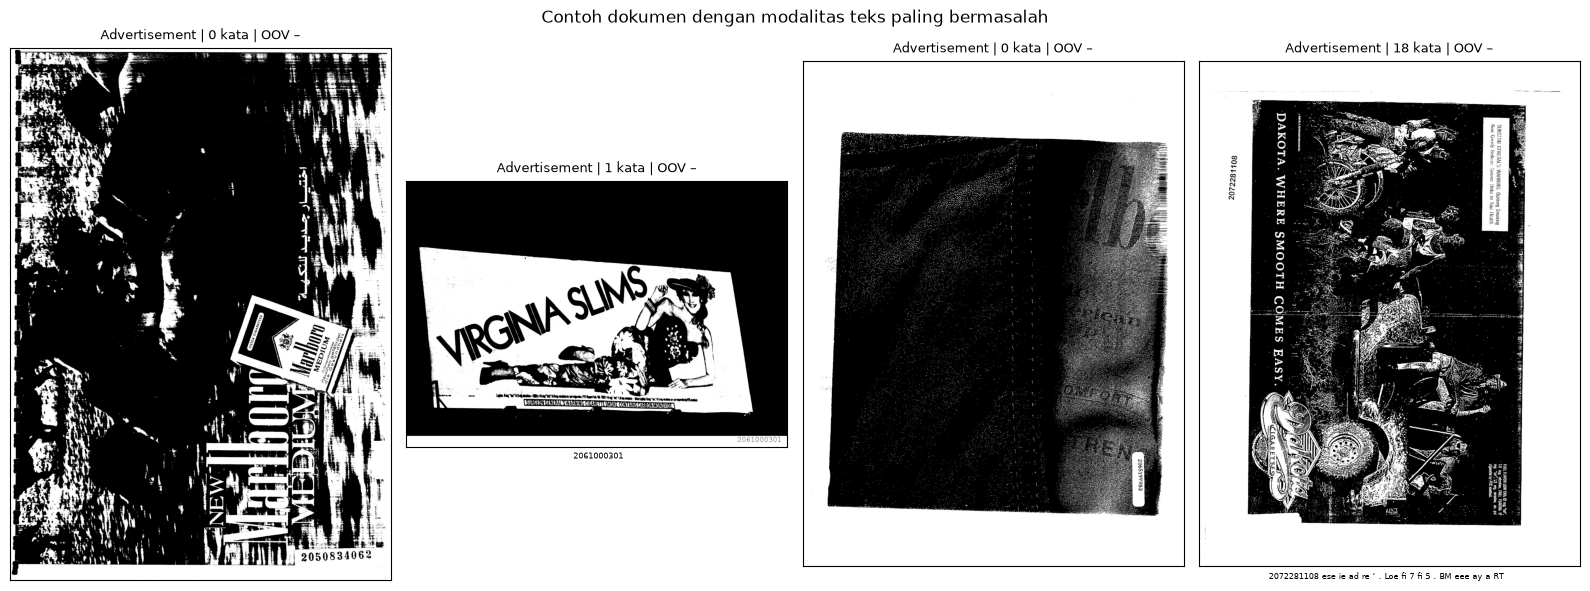

In [13]:
text_bad = df.flag_teks_kosong | df.flag_teks_pendek | df.flag_oov_tinggi
image_bad = df.flag_resolusi_rendah | df.flag_buram
cross = pd.DataFrame({
    "teks bermasalah, citra baik": (text_bad & ~image_bad),
    "citra bermasalah, teks baik": (image_bad & ~text_bad),
    "keduanya bermasalah": (text_bad & image_bad),
}).groupby(df.kelas).sum().reindex(CLASSES)
print("Dokumen per kelas yang hanya satu modalitasnya bermasalah\n"
      "(di sinilah fusion seharusnya paling menolong)")
display(cross)

worst = df[text_bad].sort_values("oov", ascending=False, na_position="first").head(4)
fig, axes = plt.subplots(1, len(worst), figsize=(16, 6))
for ax, (_, r) in zip(np.atleast_1d(axes), worst.iterrows()):
    with Image.open(manifest.loc[manifest.id == r.id, "path_citra"].iloc[0]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    snippet = texts[int(manifest.index[manifest.id == r.id][0])][:160].replace("\n", " ")
    oov_txt = "–" if pd.isna(r.oov) else f"{r.oov:.2f}"
    ax.set_title(f"{r.kelas} | {r.n_kata} kata | OOV {oov_txt}", fontsize=9)
    ax.set_xlabel(snippet, fontsize=6, wrap=True)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Contoh dokumen dengan modalitas teks paling bermasalah")
fig.tight_layout()
save_fig(fig, "eda_contoh_teks_bermasalah")
plt.show()

## H. Jalan pintas kode ID arsip

Larson et al. (2025) menemukan bahwa kode ID arsip yang tercetak di halaman Tobacco3482
sudah cukup memprediksi kelas sekitar 60%. Kode itu ikut terbaca OCR, sehingga cabang
teks bisa saja belajar jalan pintas ini.

Di sini kode ID dideteksi secara heuristik (deret ≥ 6 digit). Dari kode terpanjang di
setiap dokumen diambil tiga digit awalnya, dan sebuah classifier dilatih **hanya** dari
fitur itu. Sebagai pembanding, dipakai juga tiga karakter awal ID berkas.

Classifier ini dilatih pada bagian fit dan diuji pada test. Akurasi yang jauh di atas
kelas mayoritas berarti jalan pintas itu nyata pada data ini.

In [14]:
from sklearn.preprocessing import OneHotEncoder

def shortcut(feature_values, name):
    enc = OneHotEncoder(handle_unknown="ignore").fit(feature_values[fit_idx].reshape(-1, 1))
    clf = LogisticRegression(max_iter=3000).fit(
        enc.transform(feature_values[fit_idx].reshape(-1, 1)), y[fit_idx])
    pred = clf.predict(enc.transform(feature_values[test_idx].reshape(-1, 1)))
    return {"fitur": name, "oa": (pred == y[test_idx]).mean(),
            "macro_f1": f1_score(y[test_idx], pred, average="macro")}

df["prefiks_kode_id"] = [E.id_prefix(t) for t in texts]
shortcut_table = pd.DataFrame([
    shortcut(df.prefiks_kode_id.to_numpy(), "3 digit awal kode ID di teks OCR"),
    shortcut(manifest["id"].str[:3].to_numpy(), "3 karakter awal ID berkas"),
]).round(4)
shortcut_table["kelas_mayoritas"] = round(majority, 4)
display(shortcut_table)

has_code = (df.n_kode_id > 0).groupby(df.kelas).mean().reindex(CLASSES) * 100
print("persentase dokumen yang teks OCR-nya memuat kode ID, per kelas")
display(has_code.round(1).to_frame("% dengan kode ID"))

,fitur,oa,macro_f1,kelas_mayoritas
0,3 digit awal kode ID di teks OCR,0.2782,0.1438,0.1782
1,3 karakter awal ID berkas,0.4720,0.2757,0.1782


persentase dokumen yang teks OCR-nya memuat kode ID, per kelas


,% dengan kode ID
kelas,
Advertisement,22.6
Email,55.8
Form,37.1
Letter,26.3
Memo,20.0
News,26.1
Note,26.9
Report,23.8
Resume,40.8


## I. Simpan dataset terkurasi dan ringkasan

`manifest_kurasi.csv` berisi satu baris per dokumen:

- `split_s42`, `split_s43`, `split_s44`: `train` / `val` / `test`;
- seluruh penanda dan statistik di atas;
- `bocor_s*`: dokumen yang punya duplikat di sisi lain pembagian.

Data citra dan teks sendiri tidak disalin, karena lisensi Tobacco3482 tidak memperbolehkan
redistribusi. Manifest ini cukup untuk membangunnya kembali dari sumber aslinya.

In [15]:
curated = manifest[["id", "kelas", "path_citra", "path_teks"]].copy()
for s, sp in splits.items():
    col = np.empty(len(curated), dtype=object)
    for part in ["train", "val", "test"]:
        col[sp[part]] = part
    curated[f"split_s{s}"] = col
keep = ["n_kata", "n_kata_alfabet", "oov", "n_kode_id", "prefiks_kode_id", "lebar", "tinggi",
        "dpi_perkiraan", "kecerahan", "kontras", "rasio_tinta", "ketajaman"]
curated = pd.concat([curated, df[keep + flags + [c for c in df if c.startswith("bocor_")]]], axis=1)
assert curated[[f"split_s{s}" for s in splits]].notna().all().all()
curated.to_csv(PROC / "manifest_kurasi.csv", index=False)

flag_by_class.to_csv(REPORTS / "eda_flag_per_kelas.csv")
split_table.to_csv(REPORTS / "eda_pembagian_data.csv", index=False)
probe_table.to_csv(REPORTS / "eda_probe_fitur.csv", index=False)
comp.to_csv(REPORTS / "eda_komplementaritas.csv")
shortcut_table.to_csv(REPORTS / "eda_jalan_pintas_kode_id.csv", index=False)
top_terms.to_csv(REPORTS / "eda_kata_khas_per_kelas.csv")
summary = {
    "n_dokumen": len(curated), "rasio_kelas": round(counts.max() / counts.min(), 2),
    "ambang": {k: round(v, 3) for k, v in thresholds.items()},
    "n_tertandai": {f: int(df[f].sum()) for f in flags},
    "pasangan_kandidat_citra": len(candidates),
    "pasangan_duplikat": len(pairs),
    "pasangan_bocor": {s: len(E.split_leaks(pairs, sp)) for s, sp in splits.items()},
    "probe": probe_table.set_index("fitur")[["oa_probe", "macro_f1_probe"]].to_dict("index"),
    "kelas_mayoritas": round(majority, 4),
    "jalan_pintas": shortcut_table.set_index("fitur")[["oa", "macro_f1"]].to_dict("index"),
}
(REPORTS / "eda_ringkasan.json").write_text(json.dumps(summary, indent=1, ensure_ascii=False))
print("disimpan: data/processed/manifest_kurasi.csv, reports/eda_*.csv, reports/eda_ringkasan.json\n")
print("--- untuk laporan EDA ---")
print(json.dumps(summary, indent=1, ensure_ascii=False))

disimpan: data/processed/manifest_kurasi.csv, reports/eda_*.csv, reports/eda_ringkasan.json

--- untuk laporan EDA ---
{
 "n_dokumen": 3482,
 "rasio_kelas": 5.17,
 "ambang": {
  "teks_pendek_maks_kata": 23.0,
  "oov_tinggi_min": 0.369,
  "resolusi_rendah_maks_dpi": 203.294,
  "buram_maks_ketajaman": 788.36
 },
 "n_tertandai": {
  "flag_teks_kosong": 37,
  "flag_teks_pendek": 163,
  "flag_oov_tinggi": 172,
  "flag_resolusi_rendah": 68,
  "flag_buram": 175,
  "flag_duplikat": 9
 },
 "pasangan_kandidat_citra": 12,
 "pasangan_duplikat": 12,
 "pasangan_bocor": {
  "42": 1,
  "43": 5,
  "44": 4
 },
 "probe": {
  "citra: MobileNetV2 pretrained": {
   "oa_probe": 0.7293,
   "macro_f1_probe": 0.7099
  },
  "teks: rata-rata FastText": {
   "oa_probe": 0.6685,
   "macro_f1_probe": 0.6491
  }
 },
 "kelas_mayoritas": 0.1782,
 "jalan_pintas": {
  "3 digit awal kode ID di teks OCR": {
   "oa": 0.2782,
   "macro_f1": 0.1438
  },
  "3 karakter awal ID berkas": {
   "oa": 0.472,
   "macro_f1": 0.2757
  